# Brain–Behavior Analysis

Set `RESIDUALIZE_FOR_INR` in the parameter cell to run the matched analysis with or without income-to-needs ratio (INR) as an FC covariate. All other analysis steps are identical. Set `FULL_NETWORKS` to use FC from the full network template (`True`) or the MIDB probabilistic midb61 template (`False`).


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from matplotlib.patches import Patch
from sklearn.linear_model import LinearRegression
from sklearn.metrics import davies_bouldin_score, pairwise_distances, rand_score, silhouette_score
from statsmodels.stats.multitest import multipletests

sns.set_palette('colorblind')
sns.set_style('whitegrid')

warnings.filterwarnings('ignore')

In [2]:
INVALID_CODES = (555, 777, 888, 999)

STANDARD_FC_COVARIATES = [
    'demo_sex_v2',
    'interview_age',
    'site_id_l',
    'ehi1b',
    'mean_fd_0.20',
]

DEFAULT_CATEGORICAL_COVARIATES = {
    'demo_sex_v2',
    'site_id_l',
    'ehi1b'
}


def standardize_subject_id(subject_ids):
    return (
        subject_ids.astype(str)
        .str.replace('_', '', regex=False)
        .str.replace('^sub-', '', regex=True)
    )


def load_motion_qa(
    motion_qa_path,
    motion_column = 'mean_fd_0.20',
):
    motion_qa = pd.read_csv(motion_qa_path)

    motion_qa = motion_qa[['src_subject_id', motion_column]].copy()
    motion_qa['src_subject_id'] = standardize_subject_id(motion_qa['src_subject_id'])
    motion_qa = motion_qa.drop_duplicates(subset=['src_subject_id'])
    motion_qa[motion_column] = pd.to_numeric(motion_qa[motion_column], errors='coerce')
    return motion_qa


def merge_motion_qa(
    df,
    motion_qa_path,
    motion_column = 'mean_fd_0.20',
    how = 'left',
):
    motion_qa = load_motion_qa(motion_qa_path, motion_column=motion_column)

    merged = df.copy()
    merged['src_subject_id'] = standardize_subject_id(merged['src_subject_id'])

    if motion_column in merged.columns:
        existing_motion = merged.groupby('src_subject_id')[motion_column].first()
        merged = merged.drop(columns=[motion_column])
        merged = merged.merge(motion_qa, on='src_subject_id', how=how)
        merged[motion_column] = merged[motion_column].fillna(
            merged['src_subject_id'].map(existing_motion)
        )
    else:
        merged = merged.merge(motion_qa, on='src_subject_id', how=how)

    return merged


def _complete_covariate_mask(
    df,
    covariates,
    categorical_covariates = DEFAULT_CATEGORICAL_COVARIATES,
):
    categorical_covariates = set(categorical_covariates)
    complete = pd.Series(True, index=df.index)

    for covariate in covariates:
        is_categorical = df[covariate].dtype == 'object' or covariate in categorical_covariates
        if is_categorical:
            complete &= df[covariate].notna()
        else:
            complete &= pd.to_numeric(df[covariate], errors='coerce').notna()

    return complete

def encode_regression_covariates(
    df,
    covariates,
    categorical_covariates = DEFAULT_CATEGORICAL_COVARIATES,
):
    encoded_parts = []
    categorical_covariates = set(categorical_covariates)

    for covariate in covariates:
        if df[covariate].dtype == 'object' or covariate in categorical_covariates:
            encoded_parts.append(
                pd.get_dummies(
                    df[covariate],
                    prefix=covariate,
                    drop_first=True,
                    dtype=float,
                )
            )
        else:
            encoded_parts.append(
                pd.to_numeric(df[covariate], errors='coerce').to_frame(covariate)
            )

    return pd.concat(encoded_parts, axis=1)


def residualize_fc_profiles(
    df,
    fc_columns,
    covariates = STANDARD_FC_COVARIATES,
):
    df = df.copy()
    covariate_complete = _complete_covariate_mask(df, covariates)

    output_columns = [column + '_resid' for column in fc_columns]
    residuals = pd.DataFrame(np.nan, index=df.index, columns=output_columns)

    observed = df.loc[covariate_complete, fc_columns].to_numpy()
    covariate_matrix = encode_regression_covariates(
        df.loc[covariate_complete],
        covariates,
    )
    model = LinearRegression()
    model.fit(covariate_matrix, observed)
    predicted = model.predict(covariate_matrix)
    residuals.loc[covariate_complete, output_columns] = observed - predicted

    return pd.concat([df, residuals], axis=1)


def calculate_effect_size(
    data,
    group_col = 'kmeans_2_consensus',
    value_col = 'value',
):
    group_values = sorted(data[group_col].dropna().unique())
    if len(group_values) != 2:
        return np.nan
    group_1 = data[data[group_col] == group_values[0]][value_col].dropna()
    group_2 = data[data[group_col] == group_values[1]][value_col].dropna()

    n1 = len(group_1)
    n2 = len(group_2)

    std_1 = group_1.std(ddof=1)
    std_2 = group_2.std(ddof=1)
    pooled_std = np.sqrt(((n1 - 1) * std_1**2 + (n2 - 1) * std_2**2) / (n1 + n2 - 2))

    return (group_1.mean() - group_2.mean()) / pooled_std


def clean_group_measure(
    df,
    measure,
    group_col = 'kmeans_2_consensus',
    invalid_codes = INVALID_CODES,
):
    return (
        df[[group_col, measure]]
        .replace(list(invalid_codes), np.nan)
        .dropna()
        .copy()
    )


def compute_correlations(
    df,
    measures,
    fc_columns,
):
    results = []

    for measure in measures:
        for column in fc_columns:
            temp_df = df[[column, measure]].dropna()
            r_value, p_value = stats.pearsonr(temp_df[column], temp_df[measure])

            results.append({
                'measure': measure,
                'col': column,
                'r': r_value,
                'p': p_value,
                'n': len(temp_df),
            })

    return pd.DataFrame(results)


def apply_multiple_comparison_corrections(
    results_df,
    alpha = 0.05,
):
    if results_df.empty:
        return results_df.assign(
            p_bonf=pd.Series(dtype=float),
            sig_bonf=pd.Series(dtype=bool),
            p_fdr=pd.Series(dtype=float),
            sig_fdr=pd.Series(dtype=bool),
        )

    corrected = results_df.copy()
    n_tests = len(corrected)
    corrected['p_bonf'] = np.minimum(corrected['p'] * n_tests, 1.0)
    corrected['sig_bonf'] = corrected['p_bonf'] < alpha

    reject, p_fdr, _, _ = multipletests(
        corrected['p'],
        alpha=alpha,
        method='fdr_bh',
    )
    corrected['p_fdr'] = p_fdr
    corrected['sig_fdr'] = reject

    return corrected


def pairwise_rand_scores(df, columns):
    rand_values = []
    for i, column_i in enumerate(columns):
        for column_j in columns[i + 1:]:
            rand_values.append(rand_score(df[column_i], df[column_j]))
    return rand_values

# Data Wrangling

In [3]:
RESIDUALIZE_FOR_INR = True
FULL_NETWORKS = True
NETWORK_TEMPLATE_LABEL = 'fullnetworks' if FULL_NETWORKS else 'midb61'
RESULTS_TEMPLATE_TAG = 'fullnetworks_' if FULL_NETWORKS else ''
ANALYSIS_LABEL = 'with INR covariate' if RESIDUALIZE_FOR_INR else 'without INR covariate'
INR_VARIABLE = 'inr'
INR_RESIDUALIZATION_COVARIATE = 'inr'

# Load the clustered FC/behavior table saved by clustering.ipynb for the selected template and merge motion QA values
if FULL_NETWORKS:
    full_network_cluster_pattern = (
        'fullnetworks_meanFC_clusters_'
        f"{'with' if RESIDUALIZE_FOR_INR else 'without'}_inr_residualization_*.csv"
    )
    full_network_cluster_files = sorted(
        Path('/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final').glob(full_network_cluster_pattern)
    )
    if not full_network_cluster_files:
        raise FileNotFoundError(
            f'No {full_network_cluster_pattern} file found. Run clustering.ipynb with '
            f'FULL_NETWORKS = True and RESIDUALIZE_FC_FOR_INR = {RESIDUALIZE_FOR_INR} first.'
        )
    DATA_PATH = str(full_network_cluster_files[-1])
else:
    DATA_PATH = (
        '/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/midb61_meanFC_clusters_with_inr_residualization_2026-08-19_11-31.csv'
        if RESIDUALIZE_FOR_INR
        else '/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/midb61_meanFC_clusters_without_inr_residualization_2026-08-17_19-52.csv'
    )
if not FULL_NETWORKS:
    WRANGLED_DATA_PATH = '/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/wrangled_pMTG_FC_data_midb61_meanFC.csv'
else:
    WRANGLED_DATA_PATH = (
        '/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/wrangled_pMTG_FC_data_fullnetworks_meanFC.csv'
    )
MOTION_QA_PATH = '/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/motion_QA_results.csv'
PCA_RESULTS_DIR = Path('/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/pca_results')
EFA_RESULTS_DIR = Path('/Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/efa_results')
EFA_SCORE_MODEL_NAME = 'with_ses_residualization' if RESIDUALIZE_FOR_INR else 'without_ses_residualization'
EFA_SCORE_PREFIX = 'ses_cognitive' if RESIDUALIZE_FOR_INR else 'no_ses_cognitive'
EFA_SCORE_PATH = EFA_RESULTS_DIR / f'efa_cognitive_scores_{EFA_SCORE_MODEL_NAME}.csv'

df = pd.read_csv(DATA_PATH)
print(
    f'Clustered FC/behavior input ({Path(DATA_PATH).name}): ' 
    f'{len(df):,} rows; {df["src_subject_id"].nunique():,} unique subjects'
)

# Stop if the FC columns do not match the template selected by FULL_NETWORKS.
expected_fc_networks = (
    {'Aud', 'CO', 'DAN', 'DMN', 'FP', 'MTL', 'PMN', 'PON', 'SCAN', 'Sal', 'SMf', 'SMh', 'SMm', 'Tpole', 'VAN', 'Vis'}
    if FULL_NETWORKS
    else {'Aud', 'CO', 'DAN', 'DMN', 'FP', 'MTL', 'PMN', 'PON', 'Sal', 'SMd', 'SMl', 'Tpole', 'VAN', 'Vis'}
)
fc_networks = {str(column).split('_')[0] for column in df.columns if str(column).endswith('_fz')}
if fc_networks != expected_fc_networks:
    raise ValueError(
        f'{Path(DATA_PATH).name} has FC for networks {sorted(fc_networks)}, '
        f'which do not match the {NETWORK_TEMPLATE_LABEL} template.'
    )
print(f'FC network template: {NETWORK_TEMPLATE_LABEL} ({len(fc_networks)} networks)')
df = merge_motion_qa(df, MOTION_QA_PATH, how='left')
print(f'After left-merging motion QA: {len(df):,} rows')


def merge_add_behav_subject_columns(df, source_path, columns, source_label):
    available_columns = pd.read_csv(source_path, nrows=0).columns
    columns_to_merge = [column for column in columns if column in available_columns]
    if not columns_to_merge:
        print(f'No additional_behav {source_label} columns available to merge: {columns}')
        return df

    additional_behav_data = pd.read_csv(
        source_path,
        usecols=lambda column: column == 'src_subject_id' or column in columns_to_merge,
    )
    additional_behav_data['src_subject_id'] = standardize_subject_id(additional_behav_data['src_subject_id'])
    additional_behav_data = additional_behav_data.drop_duplicates(subset='src_subject_id')

    overlapping_columns = [column for column in columns_to_merge if column in df.columns]
    df = df.drop(columns=overlapping_columns, errors='ignore')
    df['src_subject_id'] = standardize_subject_id(df['src_subject_id'])
    return df.merge(additional_behav_data, on='src_subject_id', how='left', validate='many_to_one')


full_fc_cols = [column for column in df.columns if '_fz' in str(column) and '_full' in str(column)]
if full_fc_cols:
    df = df.drop(columns=full_fc_cols)

df = merge_add_behav_subject_columns(df, MOTION_QA_PATH, ['good_frames_0.20'], 'motion QA')
df = merge_add_behav_subject_columns(df, WRANGLED_DATA_PATH, ['accult_q2_y'], 'wrangled data')
efa_scores_df = pd.read_csv(EFA_SCORE_PATH)
efa_scores_df['src_subject_id'] = standardize_subject_id(efa_scores_df['src_subject_id'])
efa_scores_df = efa_scores_df.drop_duplicates(subset='src_subject_id')
cognitive_efa_measures = [
    col for col in efa_scores_df.columns if col.startswith(f'{EFA_SCORE_PREFIX}_EF')
]

df['src_subject_id'] = standardize_subject_id(df['src_subject_id'])
df = df.drop(columns=[col for col in cognitive_efa_measures if col in df.columns])
df = df.merge(
    efa_scores_df[['src_subject_id', *cognitive_efa_measures]],
    on='src_subject_id',
    how='left',
)
efa_factor_available = df[cognitive_efa_measures].notna().all(axis=1)
print(
    f'EFA score file ({EFA_SCORE_PATH.name}): {len(efa_scores_df):,} unique subjects; ' 
    f'{efa_scores_df[cognitive_efa_measures].notna().all(axis=1).sum():,} with complete factor scores'
)
print(f'After all left joins: {len(df):,} rows')
print(f'Rows matched to complete EFA factor scores: {efa_factor_available.sum():,}')
print(f'Running brain-behavior analysis {ANALYSIS_LABEL}')
for col in df.columns:
    print(col)


Clustered FC/behavior input (fullnetworks_meanFC_clusters_with_inr_residualization_2026-09-17_14-56.csv): 2,291 rows; 2,291 unique subjects
FC network template: fullnetworks (16 networks)


After left-merging motion QA: 2,291 rows
EFA score file (efa_cognitive_scores_with_ses_residualization.csv): 2,472 unique subjects; 2,072 with complete factor scores
After all left joins: 2,291 rows
Rows matched to complete EFA factor scores: 2,072
Running brain-behavior analysis with INR covariate
src_subject_id
mri_info_softwareversion
mri_info_studydate
rel_family_id
site_id_l
interview_age
ehi1b
ehi2b
ehi3b
ehi4b
ehi_y_ss_scoreb
demo_sex_v2
nihtbx_picvocab_uncorrected_2y
nihtbx_picvocab_agecorrected_2y
nihtbx_picvocab_v_2y
nihtbx_flanker_uncorrected_2y
nihtbx_flanker_agecorrected_2y
nihtbx_flanker_v_2y
nihtbx_pattern_uncorrected_2y
nihtbx_pattern_agecorrected_2y
nihtbx_pattern_v_2y
nihtbx_picture_uncorrected_2y
nihtbx_picture_agecorrected_2y
nihtbx_picture_v_2y
nihtbx_reading_uncorrected_2y
nihtbx_reading_agecorrected_2y
nihtbx_reading_v_2y
nihtbx_picvocab_fc_2y
nihtbx_flanker_fc_2y
nihtbx_pattern_fc_2y
nihtbx_picture_fc_2y
nihtbx_reading_fc_2y
ravlt_immediate_2y
ravlt_short_delay_

# Calculate INR for SES Analyses

In [4]:
if INR_RESIDUALIZATION_COVARIATE not in df.columns:
    wrangled_inr = pd.read_csv(
        WRANGLED_DATA_PATH,
        usecols=['src_subject_id', INR_RESIDUALIZATION_COVARIATE],
    )
    wrangled_inr['src_subject_id'] = standardize_subject_id(wrangled_inr['src_subject_id'])
    wrangled_inr = wrangled_inr.drop_duplicates(subset='src_subject_id')
    df['src_subject_id'] = standardize_subject_id(df['src_subject_id'])
    df = df.merge(wrangled_inr, on='src_subject_id', how='left', validate='many_to_one')

# FC Residualization

In [ ]:
raw_fc_cols = [col for col in df.columns if col.endswith('_fz') and '_full' not in col]

# remove the effect of sex, age, site, mean FD, handedness, and INR from the FC columns
FC_COVARIATES = [
    'demo_sex_v2',
    'interview_age',
    'site_id_l',
    'ehi1b',
    'mean_fd_0.20',
]
if RESIDUALIZE_FOR_INR:
    FC_COVARIATES = FC_COVARIATES + [INR_RESIDUALIZATION_COVARIATE]

# Drop any residual columns already present in the CSV 
existing_fc_resid_cols = [f'{col}_resid' for col in raw_fc_cols if f'{col}_resid' in df.columns]
if existing_fc_resid_cols:
    df = df.drop(columns=existing_fc_resid_cols)

fc_covariate_complete = _complete_covariate_mask(df, FC_COVARIATES)
print('Residualizing FC columns for:', FC_COVARIATES)
print(
    f'Rows with complete FC residualization covariates: ' 
    f'{fc_covariate_complete.sum():,} of {len(df):,}'
)
df = residualize_fc_profiles(df, raw_fc_cols, covariates=FC_COVARIATES)
analysis_fc_cols = [f'{col}_resid' for col in raw_fc_cols]
complete_fc_residuals = df[analysis_fc_cols].notna().all(axis=1)

print(f'Raw FC columns residualized: {len(raw_fc_cols)}')
print(f'Number of FC columns used in brain-behavior tests: {len(analysis_fc_cols)}')
print(
    f'Rows with complete residuals for all {len(analysis_fc_cols)} FC measures: ' 
    f'{complete_fc_residuals.sum():,}'
)

Residualizing FC columns for: ['demo_sex_v2', 'interview_age', 'site_id_l', 'ehi1b', 'mean_fd_0.20', 'inr']
Rows with complete FC residualization covariates: 2,291 of 2,291
Raw FC columns residualized: 64
Number of FC columns used in brain-behavior tests: 64
Rows with complete residuals for all 64 FC measures: 2,291


# Comparing groups on EF measures

In [ ]:
for measure in cognitive_efa_measures:
    df[measure] = pd.to_numeric(df[measure], errors='coerce')

cognitive_group_measures = cognitive_efa_measures.copy()
analysis_measures = cognitive_efa_measures.copy()


CLUSTER_GROUP_COL = 'kmeans_2_consensus'
print(f'Cluster group column for subtype comparisons: {CLUSTER_GROUP_COL}')
cat_measures = ['tanner_stage', 'site_id_l', 'ehi1b', 'accult_q2_y']
cont_measures = ['good_frames_0.20', 'mean_fd_0.20']
if INR_VARIABLE in df.columns:
    cont_measures.append(INR_VARIABLE)


def calculate_ttest_result(df_subset, measure):
    group_values = sorted(df_subset[CLUSTER_GROUP_COL].dropna().unique())
    if len(group_values) != 2:
        print(f'Expected two {CLUSTER_GROUP_COL} groups to test {measure}, found {group_values}')
        return None
    cluster_1 = df_subset[df_subset[CLUSTER_GROUP_COL] == group_values[0]][measure]
    cluster_2 = df_subset[df_subset[CLUSTER_GROUP_COL] == group_values[1]][measure]

    t_stat, p_val = stats.ttest_ind(cluster_1, cluster_2, equal_var=False)
    cohen_d = calculate_effect_size(df_subset, group_col=CLUSTER_GROUP_COL, value_col=measure)
    return {
        'measure': measure,
        'test': 'Welch t-test',
        't_stat': t_stat,
        'p': p_val,
        'cohen_d': cohen_d,
        'group0': group_values[0],
        'group1': group_values[1],
        'n0': len(cluster_1),
        'n1': len(cluster_2),
    }


def print_ttest_result(result, p_bonf=None):
    measure_label = result['measure']
    if 'label' in result and pd.notna(result['label']):
        measure_label = result['label']
    p_eval = p_bonf if p_bonf is not None else result['p']
    significance = 'Significant' if p_eval < 0.05 else 'No significant'
    corrected_text = f", p_bonf = {p_bonf:.7f}" if p_bonf is not None else ''
    print(
        f"{significance} difference in {measure_label} between clusters: "
        f"t_stat = {result['t_stat']:.3f}, p-value = {result['p']:.7f}"
        f"{corrected_text}"
    )
    print(f"Cohen's d = {result['cohen_d']:.3f}")
    print(
        f"Analysis sample: n={result['n0'] + result['n1']:,} "
        f"({result['group0']}: {result['n0']:,}; {result['group1']}: {result['n1']:,})"
    )
    print()


def run_chi2(df_subset, measure):
    contingency = pd.crosstab(df_subset[CLUSTER_GROUP_COL], df_subset[measure])
    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        print(f'Not enough category variation to test {measure}')
        return

    chi2, p_val, dof, expected = stats.chi2_contingency(contingency)
    denom = df_subset.shape[0] * (min(contingency.shape) - 1)
    cramer_v = np.sqrt(chi2 / denom) if denom > 0 else np.nan

    significance = 'Significant' if p_val < 0.05 else 'No significant'
    print(
        f'{significance} difference in {measure} between clusters: '
        f'chi2 = {chi2:.3f}, p-value = {p_val:.7f}'
    )
    print(f"Cramer's V = {cramer_v:.3f}")
    group_counts = df_subset[CLUSTER_GROUP_COL].value_counts().sort_index()
    group_count_text = '; '.join(f'{group}: {count:,}' for group, count in group_counts.items())
    print(f'Analysis sample: n={len(df_subset):,} ({group_count_text})')
    print()


def clean_group_measure_if_available(df, measure):
    if measure not in df.columns:
        print(f'Skipping {measure}: column is not available in this analysis dataframe.')
        return None
    return clean_group_measure(df, measure, group_col=CLUSTER_GROUP_COL)


cognitive_cluster_tests = []
for measure in cognitive_group_measures:
    temp_df = clean_group_measure_if_available(df, measure)
    if temp_df is None:
        continue
    result = calculate_ttest_result(temp_df, measure)
    if result is not None:
        cognitive_cluster_tests.append(result)

if cognitive_cluster_tests:
    cognitive_cluster_tests_df = apply_multiple_comparison_corrections(
        pd.DataFrame(cognitive_cluster_tests),
        alpha=0.05,
    )
    for _, result in cognitive_cluster_tests_df.iterrows():
        print_ttest_result(result, p_bonf=result['p_bonf'])
else:
    cognitive_cluster_tests_df = pd.DataFrame()

for measure in cat_measures:
    temp_df = clean_group_measure_if_available(df, measure)
    if temp_df is not None:
        run_chi2(temp_df, measure)

for measure in cont_measures:
    temp_df = clean_group_measure_if_available(df, measure)
    if temp_df is not None:
        result = calculate_ttest_result(temp_df, measure)
        print_ttest_result(result)

Cluster group column for subtype comparisons: kmeans_2_consensus
No significant difference in ses_cognitive_EF1 between clusters: t_stat = -1.524, p-value = 0.1275714, p_bonf = 0.2551429
Cohen's d = -0.067
Analysis sample: n=2,072 (0.0: 1,131; 1.0: 941)

No significant difference in ses_cognitive_EF2 between clusters: t_stat = -1.233, p-value = 0.2179030, p_bonf = 0.4358060
Cohen's d = -0.055
Analysis sample: n=2,072 (0.0: 1,131; 1.0: 941)

No significant difference in tanner_stage between clusters: chi2 = 2.588, p-value = 0.6290131
Cramer's V = 0.034
Analysis sample: n=2,207 (0.0: 1,214; 1.0: 993)

No significant difference in site_id_l between clusters: chi2 = 8.042, p-value = 0.9915895
Cramer's V = 0.059
Analysis sample: n=2,291 (0.0: 1,255; 1.0: 1,036)

No significant difference in ehi1b between clusters: chi2 = 1.851, p-value = 0.7632139
Cramer's V = 0.028
Analysis sample: n=2,291 (0.0: 1,255; 1.0: 1,036)

No significant difference in accult_q2_y between clusters: chi2 = 0.003, p-

# Network FC - EFA Significant Correlations

In [ ]:
sample_columns = list(dict.fromkeys([*cognitive_efa_measures, *analysis_fc_cols]))
family_intersection_n = df[sample_columns].dropna().shape[0]
n_cognitive_tests = len(cognitive_efa_measures) * len(analysis_fc_cols)
alpha = 0.05
trend_alpha = 0.001

dfree = family_intersection_n - 2
if dfree > 0:
    trend_t_crit = stats.t.ppf(1 - trend_alpha / 2, dfree)
    r_trend = np.sqrt(trend_t_crit**2 / (trend_t_crit**2 + dfree))
else:
    r_trend = np.nan


results_df = compute_correlations(
    df,
    cognitive_efa_measures,
    analysis_fc_cols,
)
results_df = apply_multiple_comparison_corrections(results_df, alpha=0.05)
results_df['abs_r'] = results_df['r'].abs()
cognitive_results_df = results_df.copy()
cognitive_efa_results_df = cognitive_results_df.copy()

sig_cols = []
print()
print('Significant cognitive EFA - FC correlations:')
fdr_results = cognitive_efa_results_df[cognitive_efa_results_df['sig_fdr']].sort_values('p_fdr')

if fdr_results.empty:
    print('None')
else:
    for _, row in fdr_results.iterrows():
        print(
            f"{row['col']} vs {row['measure']}: "
            f"r = {row['r']:.4f}, p = {row['p']:.4g}, p_fdr = {row['p_fdr']:.4g}, n = {row['n']}"
        )
        sig_cols.append(row['col'])

print()
print('Top 10 cognitive EFA factor-FC correlations by absolute r-value:')
top_efa_correlations = cognitive_efa_results_df.reindex(
    cognitive_efa_results_df['abs_r'].sort_values(ascending=False).index
).head(10)
display(top_efa_correlations)


# Save the cognitive EFA-FC correlation family so figures.ipynb can compare the
# INR-residualized and non-INR-residualized variants without rerunning this notebook.
cognitive_efa_results_df['fc_residualization'] = (
    'standard_covariates_with_inr' if RESIDUALIZE_FOR_INR else 'standard_covariates_without_inr'
)
cognitive_efa_results_df['n_tests_in_fdr_family'] = len(cognitive_efa_results_df)
cognitive_efa_results_path = PCA_RESULTS_DIR / (
    f'fc_cognitive_efa_correlations_{RESULTS_TEMPLATE_TAG}'
    f"{'with' if RESIDUALIZE_FOR_INR else 'without'}_inr_residualization.csv"
)
cognitive_efa_results_df.to_csv(cognitive_efa_results_path, index=False)
print('Saved cognitive EFA-FC correlations to:', cognitive_efa_results_path)


Significant cognitive EFA - FC correlations:
None

Top 10 cognitive EFA factor-FC correlations by absolute r-value:


,measure,col,r,p,n,p_bonf,sig_bonf,p_fdr,sig_fdr,abs_r
33,ses_cognitive_EF1,DMN_right_R_fz_resid,0.073120,0.000866,2072,0.110844,False,0.073116,False,0.073120
25,ses_cognitive_EF1,MTL_left_R_fz_resid,0.071413,0.001142,2072,0.146232,False,0.073116,False,0.071413
69,ses_cognitive_EF2,FP_left_R_fz_resid,-0.067017,0.002272,2072,0.290826,False,0.096942,False,0.067017
5,ses_cognitive_EF1,FP_left_R_fz_resid,-0.059455,0.006787,2072,0.868795,False,0.150945,False,0.059455
64,ses_cognitive_EF2,DMN_left_L_fz_resid,0.059401,0.006838,2072,0.875270,False,0.150945,False,0.059401
15,ses_cognitive_EF1,CO_left_R_fz_resid,-0.059152,0.007076,2072,0.905668,False,0.150945,False,0.059152
47,ses_cognitive_EF1,CO_right_R_fz_resid,-0.056672,0.009875,2072,1.000000,False,0.154745,False,0.056672
29,ses_cognitive_EF1,PON_left_R_fz_resid,0.056103,0.010643,2072,1.000000,False,0.154745,False,0.056103
1,ses_cognitive_EF1,DMN_left_R_fz_resid,0.055469,0.011560,2072,1.000000,False,0.154745,False,0.055469
61,ses_cognitive_EF1,PON_right_R_fz_resid,0.055122,0.012089,2072,1.000000,False,0.154745,False,0.055122


Saved cognitive EFA-FC correlations to: /Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/pca_results/fc_cognitive_efa_correlations_fullnetworks_with_inr_residualization.csv


# Network FC - INR Correlations

Test associations between INR and pMTG FC. Because this notebook already residualizes FC for INR (`RESIDUALIZE_FOR_INR = True`), these correlations are expected to be attenuated toward zero.

In [8]:
inr_fc_results_df = compute_correlations(
    df,
    [INR_VARIABLE],
    analysis_fc_cols,
)
inr_fc_results_df = apply_multiple_comparison_corrections(inr_fc_results_df, alpha=0.05)
inr_fc_results_df = inr_fc_results_df.rename(
    columns={'measure': 'ses_measure', 'col': 'fc_measure'}
)
inr_fc_results_df['abs_r'] = inr_fc_results_df['r'].abs()
inr_fc_results_df['fc_residualization'] = 'standard_covariates_with_inr'
inr_fc_results_df['n_tests_in_fdr_family'] = len(inr_fc_results_df)
inr_fc_results_df = inr_fc_results_df.sort_values(
    ['p_fdr', 'p', 'abs_r'],
    ascending=[True, True, False],
).reset_index(drop=True)

print('FDR-significant FC-INR correlations:')
display(inr_fc_results_df[inr_fc_results_df['sig_fdr']])
print('Top 20 FC-INR correlations by absolute r-value:')
display(inr_fc_results_df.sort_values('abs_r', ascending=False).head(20))

inr_fc_results_path = PCA_RESULTS_DIR / f'fc_ses_correlations_{RESULTS_TEMPLATE_TAG}with_inr_residualization.csv'
inr_fc_results_df.to_csv(inr_fc_results_path, index=False)
print('Saved FC-INR correlations to:', inr_fc_results_path)


FDR-significant FC-INR correlations:


,ses_measure,fc_measure,r,p,n,p_bonf,sig_bonf,p_fdr,sig_fdr,abs_r,fc_residualization,n_tests_in_fdr_family


Top 20 FC-INR correlations by absolute r-value:


,ses_measure,fc_measure,r,p,n,p_bonf,sig_bonf,p_fdr,sig_fdr,abs_r,fc_residualization,n_tests_in_fdr_family
0,inr,Sal_right_L_fz_resid,-7.463648e-16,1.0,2291,1.0,False,1.0,False,7.463648e-16,standard_covariates_with_inr,64
1,inr,SMh_left_L_fz_resid,6.557255e-16,1.0,2291,1.0,False,1.0,False,6.557255e-16,standard_covariates_with_inr,64
2,inr,VAN_left_L_fz_resid,-6.453171e-16,1.0,2291,1.0,False,1.0,False,6.453171e-16,standard_covariates_with_inr,64
3,inr,SMm_left_L_fz_resid,6.383782e-16,1.0,2291,1.0,False,1.0,False,6.383782e-16,standard_covariates_with_inr,64
4,inr,DMN_left_R_fz_resid,5.846018e-16,1.0,2291,1.0,False,1.0,False,5.846018e-16,standard_covariates_with_inr,64
5,inr,Tpole_right_L_fz_resid,-5.334275e-16,1.0,2291,1.0,False,1.0,False,5.334275e-16,standard_covariates_with_inr,64
6,inr,DMN_right_R_fz_resid,5.256212e-16,1.0,2291,1.0,False,1.0,False,5.256212e-16,standard_covariates_with_inr,64
7,inr,SMf_left_L_fz_resid,5.186823e-16,1.0,2291,1.0,False,1.0,False,5.186823e-16,standard_covariates_with_inr,64
8,inr,Sal_left_R_fz_resid,5.160802e-16,1.0,2291,1.0,False,1.0,False,5.160802e-16,standard_covariates_with_inr,64
9,inr,SCAN_left_L_fz_resid,5.065393e-16,1.0,2291,1.0,False,1.0,False,5.065393e-16,standard_covariates_with_inr,64


Saved FC-INR correlations to: /Users/emk/Documents/Documents - Ron Weasley V/Research/Verbal-Ability/Final/pca_results/fc_ses_correlations_fullnetworks_with_inr_residualization.csv


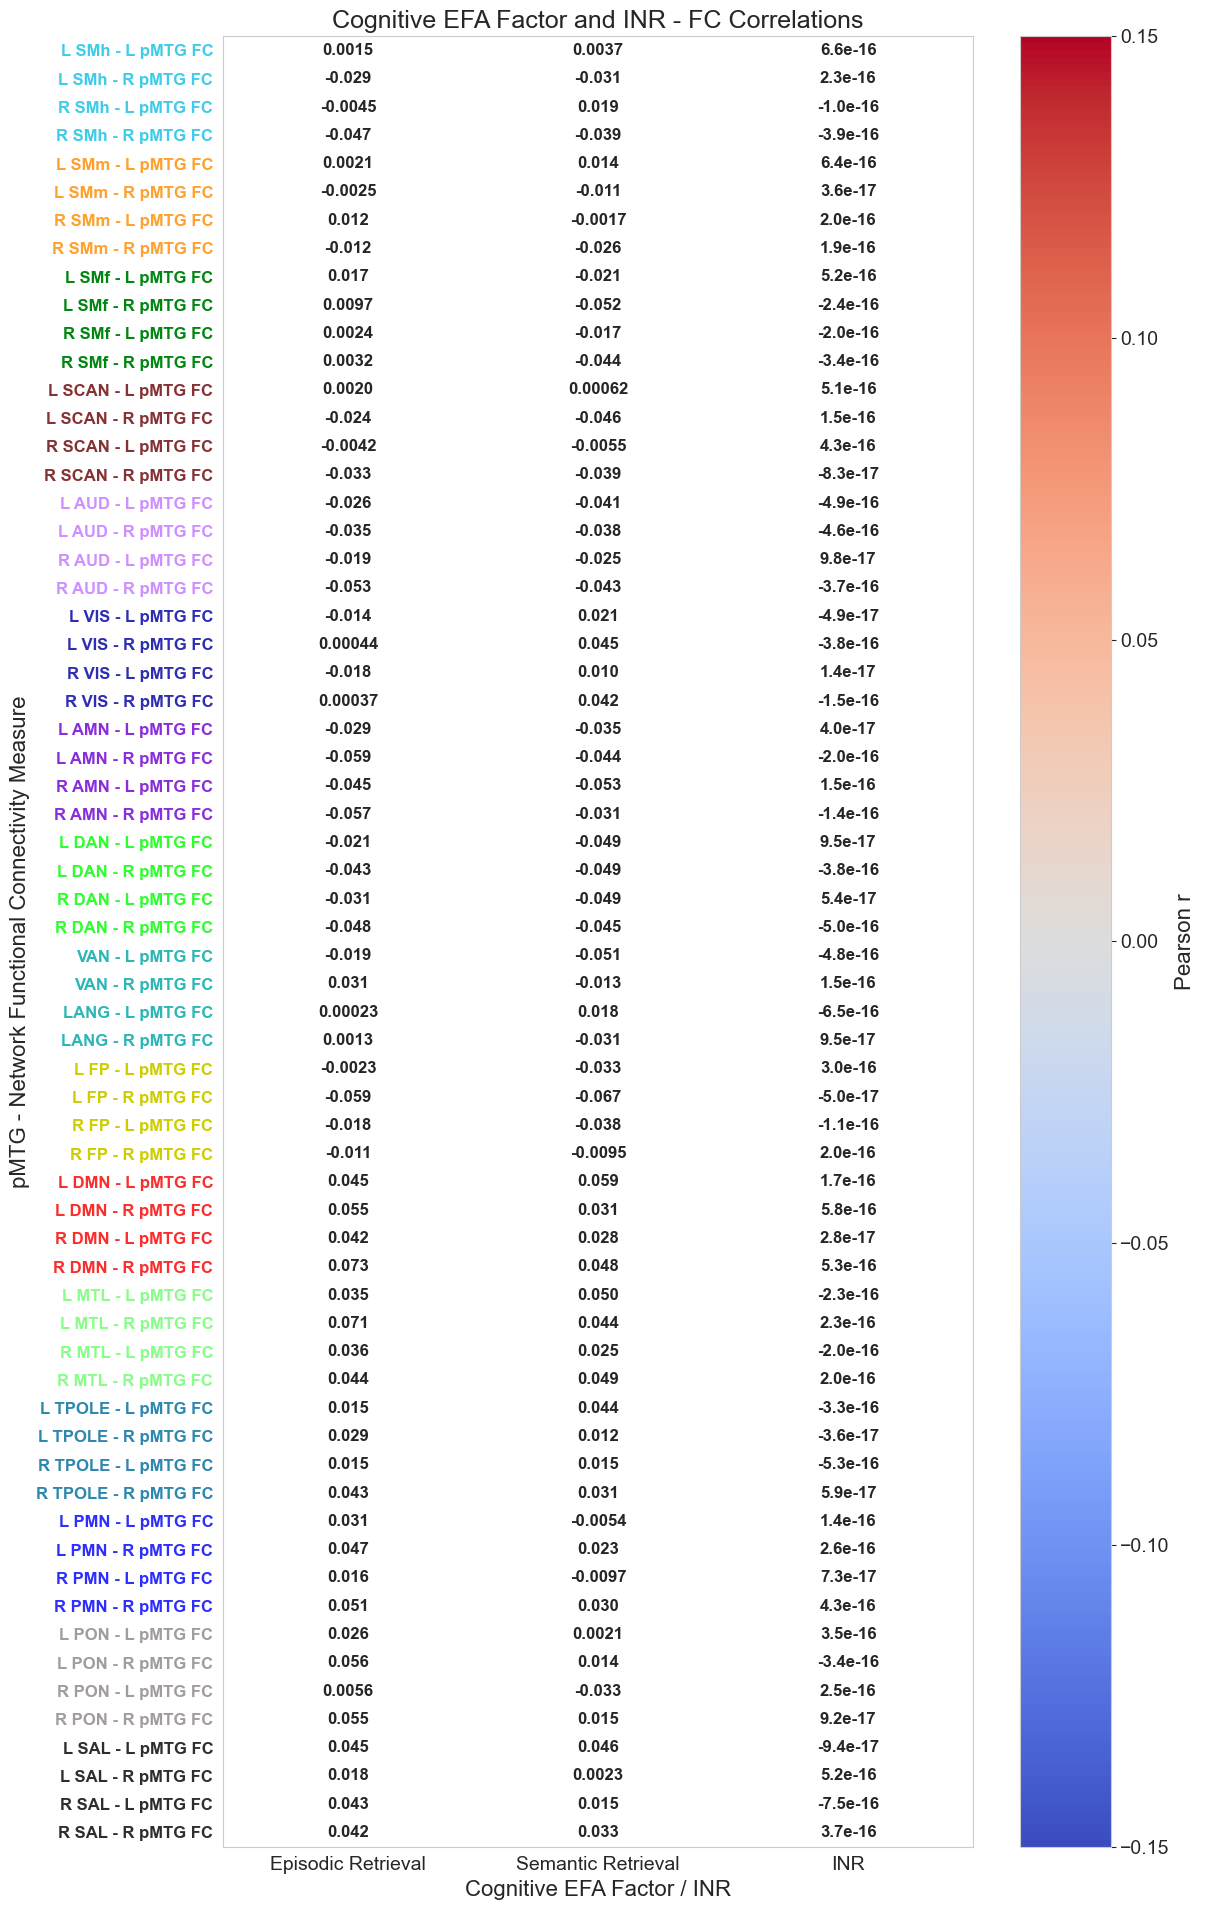

In [9]:
# Plot every cognitive EFA factor and INR correlation, shading only FDR-significant cells.
inr_heat_source = inr_fc_results_df.rename(columns={'ses_measure': 'measure', 'fc_measure': 'col'})
combined_efa_inr_results_df = pd.concat([cognitive_efa_results_df, inr_heat_source], ignore_index=True)
plot_df = combined_efa_inr_results_df.copy()

if plot_df.empty:
    print('No cognitive EFA factor or INR correlations available to plot.')
else:
    plot_df['network'] = plot_df['col'].str.split('_').str[0]
    plot_df['network'] = plot_df['network'].replace({'CO': 'AMN', 'Aud': 'AUD', 'Sal': 'SAL'})

    seed_net_raw = plot_df['col'].str.split('_').str[0]
    seed_hemi = plot_df['col'].str.split('_').str[1].str[0].str.upper()
    seed_lr = plot_df['col'].str.split('_').str[2]

    seed_net = seed_net_raw.replace(
        {'CO': 'AMN', 'Aud': 'AUD', 'Sal': 'SAL', 'Tpole': 'TPOLE', 'Vis': 'VIS'}
    )
    seed_net = np.where((seed_net_raw == 'VAN') & (seed_hemi == 'L'), 'LANG', seed_net)

    plot_df['network'] = seed_net
    plot_df['hemi'] = seed_hemi
    plot_df['seed_label'] = np.where(
        seed_net_raw == 'VAN',
        seed_net + ' - ' + seed_lr + ' pMTG FC',
        seed_hemi + ' ' + seed_net + ' - ' + seed_lr + ' pMTG FC',
    )

    measure_map = dict(zip(cognitive_efa_measures, ['Episodic Retrieval', 'Semantic Retrieval']))
    measure_map[INR_VARIABLE] = 'INR'
    plot_df['measure_label'] = plot_df['measure'].map(measure_map).fillna(plot_df['measure'])

    network_colors = {
        'DMN': '#fb2e2e', 'SMd': '#40cce9', 'LANG': '#2DB6B6FF', 'TPOLE': '#2e87ae',
        'AUD': '#ce8fff', 'AMN': '#8a2edb', 'DAN': '#2efe2e', 'FP': '#cdcd00ff',
        'MTL': '#89fd89', 'PMN': '#2e2eff', 'PON': '#a29c9cff', 'SAL': '#2e2e2e',
        'VAN': '#2DB6B6FF', 'SMl': '#ffa12e', 'VIS': '#2e2eb3',
        # Networks that only exist in the full network template
        'SMh': '#40cce9', 'SMm': '#ffa12e', 'SMf': '#008611', 'SCAN': '#863235',
    }

    heat = plot_df.pivot_table(index='seed_label', columns='measure_label', values='r', aggfunc='first')
    sig_heat = plot_df.pivot_table(
        index='seed_label', columns='measure_label', values='sig_fdr', aggfunc='first'
    )
    column_order = ['Episodic Retrieval', 'Semantic Retrieval', 'INR']
    heat = heat.reindex(columns=[column for column in column_order if column in heat.columns])
    sig_heat = sig_heat.reindex(index=heat.index, columns=heat.columns).fillna(False).astype(bool)
    row_info = plot_df.drop_duplicates('seed_label').set_index('seed_label').loc[heat.index]

    blue_network_order = ['SMd', 'SMl', 'SMh', 'SMm', 'SMf', 'SCAN', 'AUD', 'VIS', 'AMN', 'DAN', 'VAN', 'LANG', 'FP']
    red_network_order = ['DMN', 'MTL', 'TPOLE', 'PMN', 'PON', 'SAL']
    network_order = blue_network_order + red_network_order

    row_info['network_order'] = row_info['network'].map({network: i for i, network in enumerate(network_order)})
    heat = heat.loc[row_info.sort_values(['network_order', 'hemi']).index]
    sig_heat = sig_heat.loc[heat.index, heat.columns]
    row_info = row_info.loc[heat.index]
    row_networks = row_info['network']

    fig, ax = plt.subplots(figsize=(12, max(6, 0.3 * len(heat))))
    heatmap_cmap = plt.get_cmap('coolwarm').copy()
    heatmap_cmap.set_bad('white')
    shaded_heat = np.ma.masked_where(~sig_heat.to_numpy(), heat.to_numpy(dtype=float))
    im = ax.imshow(shaded_heat, aspect='auto', cmap=heatmap_cmap, vmin=-0.15, vmax=0.15)
    ax.grid(False)
    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns, ha='center', fontsize=14)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index, fontsize=12)

    for y, label in enumerate(ax.get_yticklabels()):
        net = row_networks.iloc[y]
        label.set_color(network_colors.get(net, 'black'))
        label.set_fontweight('bold')

    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            val = heat.iloc[i, j]
            if pd.notna(val):
                ax.text(j, i, f'{val:#.2g}', ha='center', va='center', fontsize=12, fontweight='bold')

    legend_handles = []
    for network in network_order:
        if network in set(row_networks):
            if network == 'VAN':
                label = 'LANG/VAN'
            elif network == 'LANG':
                continue
            else:
                label = network
            legend_handles.append(Patch(color=network_colors[network], label=label))

    cbar = fig.colorbar(im, ax=ax)
    # increase x and y tick label font size
    cbar.ax.tick_params(labelsize=14)
    cbar.set_label('Pearson r', fontsize=16)

    ax.set_title(f'Cognitive EFA Factor and INR - FC Correlations', fontsize=18)
    ax.set_xlabel('Cognitive EFA Factor / INR', fontsize=16)
    ax.set_ylabel('pMTG - Network Functional Connectivity Measure', fontsize=16)

    plt.tight_layout()
    plt.show()

In [ ]:
# print the correlation between the two cognitive EFA factors
if len(cognitive_efa_measures) >= 2:
    efa_factor_corr = pg.corr(df[cognitive_efa_measures[0]], df[cognitive_efa_measures[1]])
    efa_pair_n = df[cognitive_efa_measures[:2]].dropna().shape[0]
    print(
        f"Correlation between {cognitive_efa_measures[0]} and {cognitive_efa_measures[1]} "
        f"(pairwise complete n={efa_pair_n:,}):"
    )
    print(efa_factor_corr)

Correlation between ses_cognitive_EF1 and ses_cognitive_EF2 (pairwise complete n=2,072):
            n         r         CI95%          p-val        BF10  power
pearson  2072  0.482818  [0.45, 0.52]  1.803732e-121  4.246e+117    1.0


# Subtype Sizes and Internal Validation Metrics

In [11]:
# Count subtype sizes for each clustering solution used in the paper figures.
kmeans_group_counts = df['kmeans_2_consensus'].value_counts()
print(f'K-means subtype sample: n={kmeans_group_counts.sum():,}')
print(kmeans_group_counts)

louvain_group_counts = df['louvain_consensus'].value_counts()
print(f'Louvain subtype sample: n={louvain_group_counts.sum():,}')
print(louvain_group_counts)

infomap_group_counts = df['infomap_community_2'].value_counts()
print(f'Infomap subtype sample: n={infomap_group_counts.sum():,}')
print(infomap_group_counts)

# Recalculate internal validation metrics for the final two-subtype
# K-means, Louvain, and Infomap solutions using this notebook's residualized FC profiles.
cluster_validation_solutions = [
    ('K-means', 2, 'kmeans_2_consensus'),
    ('Louvain', 2, 'louvain_consensus'),
    ('Infomap', 2, 'infomap_community_2'),
]
cluster_validation_label_cols = [column for _, _, column in cluster_validation_solutions]
missing_cluster_validation_cols = [
    column for column in cluster_validation_label_cols if column not in df.columns
]

cluster_validation_rows = []
if missing_cluster_validation_cols:
    print('Cannot calculate all clustering metrics; missing labels:', missing_cluster_validation_cols)
else:
    cluster_validation_complete = df[
        [*analysis_fc_cols, *cluster_validation_label_cols]
    ].notna().all(axis=1)
    cluster_validation_X = df.loc[
        cluster_validation_complete, analysis_fc_cols
    ].to_numpy(dtype=float)
    correlation_distances = pairwise_distances(cluster_validation_X, metric='correlation')

    print()
    print(
        f'Clustering validation sample: ' 
        f'{cluster_validation_complete.sum():,} of {len(df):,}'
    )

    for algorithm, requested_subtypes, label_col in cluster_validation_solutions:
        labels = df.loc[cluster_validation_complete, label_col].to_numpy()
        observed_subtypes = np.unique(labels).size
        if observed_subtypes != requested_subtypes:
            print(
                f'Skipping {algorithm} {requested_subtypes}-subtype solution: ' 
                f'{label_col} contains {observed_subtypes} observed labels.'
            )
            continue

        silhouette = silhouette_score(correlation_distances, labels, metric='precomputed')
        dbi = davies_bouldin_score(cluster_validation_X, labels)
        cluster_validation_rows.append({
            'algorithm': algorithm,
            'n_subtypes': requested_subtypes,
            'label_column': label_col,
            'n': len(labels),
            'silhouette_correlation': silhouette,
            'davies_bouldin_euclidean': dbi,
        })
        print(
            f'{algorithm} {requested_subtypes}-subtype solution ({label_col}): ' 
            f'n={len(labels):,}, silhouette={silhouette:.4f}, DBI={dbi:.4f}'
        )

cluster_validation_df = pd.DataFrame(cluster_validation_rows)
display(cluster_validation_df)

K-means subtype sample: n=2,291
kmeans_2_consensus
0.0    1255
1.0    1036
Name: count, dtype: int64
Louvain subtype sample: n=2,291
louvain_consensus
0    1195
1    1096
Name: count, dtype: int64
Infomap subtype sample: n=2,291
infomap_community_2
0    1205
1    1086
Name: count, dtype: int64

Clustering validation sample: 2,291 of 2,291
K-means 2-subtype solution (kmeans_2_consensus): n=2,291, silhouette=0.3190, DBI=1.8569
Louvain 2-subtype solution (louvain_consensus): n=2,291, silhouette=0.3195, DBI=1.8670
Infomap 2-subtype solution (infomap_community_2): n=2,291, silhouette=0.3197, DBI=1.8650


,algorithm,n_subtypes,label_column,n,silhouette_correlation,davies_bouldin_euclidean
0,K-means,2,kmeans_2_consensus,2291,0.318969,1.856882
1,Louvain,2,louvain_consensus,2291,0.319481,1.867030
2,Infomap,2,infomap_community_2,2291,0.319718,1.864998


# Comparing Clustering Algorithms

1001


Mean Rand Index between louvain permutation columns: 0.99634698277197364379986765925423242151737213
1001


Mean Rand Index between kmeans permutation columns: 0.98944178572423968631710522458888590335845947
Louvain Permutation Rand Scores:
Range: 0.9913044969969826 - 1.0
Mean: 0.9963469827719736
SD: 0.003408510707966836
KMeans Run Rand Scores:
Range: 0.9749930904869825 - 1.0
Mean: 0.9894417857242397
SD: 0.010248344791374361


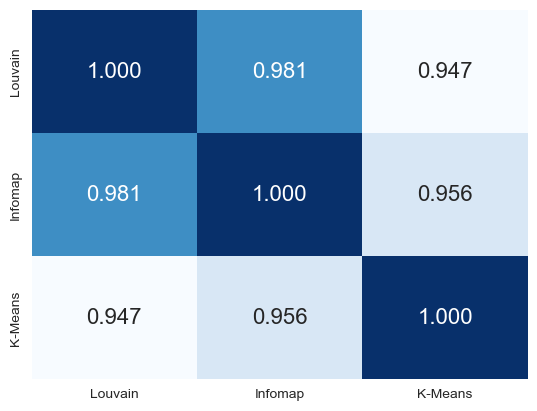

In [13]:
# Compare agreement among Louvain, Infomap, and k-means subtype assignments.
subtype_cols = ['louvain_consensus', 'infomap_community_2', 'kmeans_2_consensus']
matrix = np.zeros((len(subtype_cols), len(subtype_cols)))

for i in range(len(subtype_cols)):
    for j in range(len(subtype_cols)):
        matrix[i, j] = rand_score(df[subtype_cols[i]], df[subtype_cols[j]])

labels = ['Louvain', 'Infomap', 'K-Means']
sns.heatmap(matrix, annot=True, cmap='Blues', xticklabels=labels, yticklabels=labels, fmt='.3f', cbar=False, annot_kws={'size': 16, 'font': 'Arial'})

# Summarize stability across Louvain permutation columns
louvain_perm_cols = [col for col in df.columns if 'louvain_community' in col and 'consensus' not in col and 'subtypes' not in col]
print(len(louvain_perm_cols))
louvain_rand_values = pairwise_rand_scores(df, louvain_perm_cols) if len(louvain_perm_cols) > 1 else []
if louvain_rand_values:
    print(f'Mean Rand Index between louvain permutation columns: {np.mean(louvain_rand_values):.44f}')
else:
    print('Not enough Louvain permutation columns to calculate pairwise Rand scores.')

# Summarize stability across k-means runs
kmeans_perm_cols = [col for col in df.columns if 'kmeans' in col and '_run_' in col and 'consensus' not in col and 'subtypes' not in col]
print(len(kmeans_perm_cols))
kmeans_rand_values = pairwise_rand_scores(df, kmeans_perm_cols) if len(kmeans_perm_cols) > 1 else []
if kmeans_rand_values:
    print(f'Mean Rand Index between kmeans permutation columns: {np.mean(kmeans_rand_values):.44f}')
else:
    print('Not enough k-means run columns to calculate pairwise Rand scores.')

if louvain_rand_values:
    print('Louvain Permutation Rand Scores:')
    print('Range:', min(louvain_rand_values), '-', max(louvain_rand_values))
    print('Mean:', np.mean(louvain_rand_values))
    print('SD:', np.std(louvain_rand_values))

if kmeans_rand_values:
    print('KMeans Run Rand Scores:')
    print('Range:', min(kmeans_rand_values), '-', max(kmeans_rand_values))
    print('Mean:', np.mean(kmeans_rand_values))
    print('SD:', np.std(kmeans_rand_values))